# OGM: smooth convex minimization

Let $f$ be convex and $L$-smooth on a finite-dimensional Euclidean space, with $L>0$ and $R\ge0$.
Assume $\nabla f(x_\star)=0$, $\|x_0-x_\star\|^2\le R^2$, and $z_0=x_0$.
For integer $N\ge1$, the metric is $f(x_N)-f(x_\star)$.
Set $\theta_{-1}=0$ and
$$\theta_k=\frac{1+\sqrt{1+4\theta_{k-1}^2}}2\quad(0\le k<N),\qquad
\theta_N=\frac{1+\sqrt{1+8\theta_{N-1}^2}}2.$$
For $k=0,\ldots,N-1$, perform
$$y_{k+1}=x_k-\frac1L\nabla f(x_k),\qquad
z_{k+1}=z_k-\frac{2\theta_k}{L}\nabla f(x_k),$$
$$x_{k+1}=\left(1-\frac1{\theta_{k+1}}\right)y_{k+1}+\frac{z_{k+1}}{\theta_{k+1}}.$$
The special terminal recurrence is part of the algorithm. Finite PEP samples use floating-point theta values; arbitrary-horizon proof remains a later obligation.


## Proof Statement

### Theorem
Let $f$ be convex and $L$-smooth, with $L>0$, $R\ge0$, $\nabla f(x_{\star})=0$, and $\|x_{0}-x_{\star}\|\le R$.
Run the stated OGM iteration for any integer $N\ge1$, including its special terminal coefficient. Write $g_{k}=\nabla f(x_{k})$, $T=\theta_{N}$, $d_{0}=x_{0}-x_{\star}$, and $q_{N}=z_{N}-x_{\star}-Tg_{N}/L$.
Define $V_{0}=0$ and, for $1\le k<N$,
$$V_{k}=\frac{L}{2T^{2}}\left(\|z_{k+1}-x_{\star}\|^{2}-\|d_{0}\|^{2}\right)
-\frac{\theta_{k}^{2}}{LT^{2}}\|g_{k}\|^{2}
+\frac{2\theta_{k}^{2}}{T^{2}}\left(f(x_{k})-f(x_{\star})\right).$$
At the terminal index set
$$V_{N}=f(x_{N})-f(x_{\star})+\frac{L}{2T^{2}}\left(\|q_{N}\|^{2}-\|d_{0}\|^{2}\right).$$
Then $V_{N}\le\cdots\le V_{1}\le V_{0}=0$, and consequently
$$\boxed{f(x_{N})-f(x_{\star})\le\frac{LR^{2}}{2\theta_{N}^{2}}.}$$
For $N=1$ the interior formula has an empty index range, and the terminal formula still applies.


### Proof outline
For two evaluation points define the smooth convex interpolation residual
$$I_{i,j}=f(x_{j})-f(x_{i})+\langle g_{j},x_{i}-x_{j}\rangle+\frac{1}{2L}\|g_{i}-g_{j}\|^{2}\le0,$$
where $x_{\star}$ is the stationary minimizer and $g_{\star}=0$.
The potential consists of the norm difference with coefficient $L/(2T^{2})$, the gradient term $-\theta_{k}^{2}\|g_{k}\|^{2}/(LT^{2})$, and the gap term $2\theta_{k}^{2}(f(x_{k})-f(x_{\star}))/T^{2}$; its terminal expression is the gap plus $L(\|q_{N}\|^{2}-\|d_{0}\|^{2})/(2T^{2})$.

For $N\ge2$, direct use of the updates and $\theta_{k+1}^{2}-\theta_{k+1}=\theta_{k}^{2}$ gives
$$V_{1}=\frac{2I_{\star,0}+2\theta_{1}I_{\star,1}+2\theta_{0}^{2}I_{0,1}}{T^{2}},$$
$$V_{k+1}-V_{k}=\frac{2\theta_{k+1}}{T^{2}}I_{\star,k+1}+\frac{2\theta_{k}^{2}}{T^{2}}I_{k,k+1}\quad(1\le k\le N-2).$$
The distinct terminal recurrence $T^{2}-T=2\theta_{N-1}^{2}$ gives
$$V_{N}-V_{N-1}=\frac1T I_{\star,N}+\frac{2\theta_{N-1}^{2}}{T^{2}}I_{N-1,N}.$$
For $N=1$, $\theta_{0}=1$ and $T=2$; the exact exceptional identity is
$$V_{1}=\tfrac12\left(I_{\star,0}+I_{\star,1}+I_{0,1}\right).$$
All multipliers are positive. Hence every displayed increment is nonpositive and $V_{N}\le0$.
Finally,
$$f(x_{N})-f(x_{\star})-\frac{LR^{2}}{2T^{2}}
=V_{N}-\frac{L}{2T^{2}}\|q_{N}\|^{2}
+\frac{L}{2T^{2}}\left(\|d_{0}\|^{2}-R^{2}\right)\le0.$$
The last two terms are nonpositive by squared-norm nonnegativity and the initial condition. This argument includes $R=0$ without dividing by $R$.
The exact symbolic cells below verify every identity in all scalar components; finite-sample numerical agreement is not used as the proof.


In [1]:
import json
import sys
from math import sqrt
from pathlib import Path

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary")]
import matplotlib.pyplot as plt  # noqa: E402 -- approved source path must be set first
import numpy as np  # noqa: E402
import pepflow as pf  # noqa: E402

assert Path(pf.__file__).resolve().parent == repo_root / "pepflow"
print("Framework:", pf.__file__)

Framework: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\ogm\r02\supplementary\approved\pepflow\__init__.py


In [2]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)

In [3]:
def theta_sequence(N):
    """Numerical theta coefficients for a finite PEP sample, including theta_N."""
    if N < 1:
        raise ValueError("N must be positive")
    theta = []
    previous = 0.0
    for _ in range(N):
        previous = (1 + sqrt(1 + 4 * previous**2)) / 2
        theta.append(previous)
    theta.append((1 + sqrt(1 + 8 * previous**2)) / 2)
    return theta


def make_ctx_ogm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0", "z_0"])
    z = x
    f.set_stationary_point("x_star")
    theta = theta_sequence(N)
    for k in range(N):
        g = f.grad(x)
        g.add_tag(f"g_{k}")
        y = x - g / L
        y.add_tag(f"y_{k + 1}")
        z = z - (2 * theta[k] / L) * g
        z.add_tag(f"z_{k + 1}")
        x = (1 - 1 / theta[k + 1]) * y + z / theta[k + 1]
        x.add_tag(f"x_{k + 1}")
    f.grad(x).add_tag(f"g_{N}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_ogm(f"ogm_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(ctx["x_star"]))
    return ctx, pb, f

In [4]:
sample_ctx, sample_pb, sample_f = get_pep_setup(6, {"L": 1, "R": 1})
print("Context and metric constructed:", sample_pb.performance_metric)

Context and metric constructed: f(x_6)-f(x_star)


## Numerical evidence
This is the saved single B1 sweep, not a repeated solve. Every solve used CLARABEL defaults and returned optimal.

N=1: PEP=0.1249999997, candidate=0.1250000000, status=optimal
N=2: PEP=0.0618941831, candidate=0.0618941824, status=optimal
N=3: PEP=0.0376923986, candidate=0.0376923972, status=optimal
N=4: PEP=0.0255839452, candidate=0.0255839420, status=optimal
N=5: PEP=0.0185881398, candidate=0.0185881367, status=optimal
N=6: PEP=0.0141559673, candidate=0.0141559659, status=optimal
N=7: PEP=0.0111604195, candidate=0.0111604169, status=optimal
Maximum absolute discrepancy: 3.1168371598944145e-09


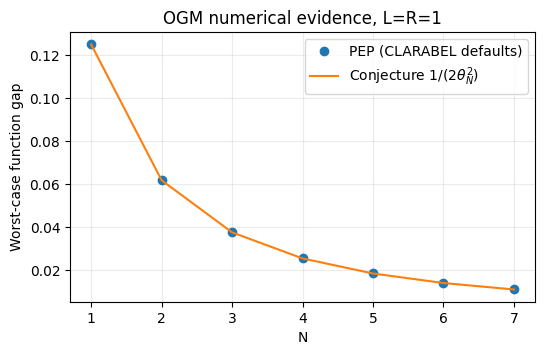

In [5]:
b1 = json.loads((notebook_dir / "state" / "ogm_b1.json").read_text())
rows = b1["sweep_results"]
Ns = np.array([r["N"] for r in rows])
values = np.array([r["opt_value"] for r in rows])
candidate = np.array([1 / (2 * theta_sequence(r["N"])[-1] ** 2) for r in rows])
for row, guess in zip(rows, candidate):
    print(
        f"N={row['N']}: PEP={row['opt_value']:.10f}, candidate={guess:.10f}, status={row['status']}"
    )
error = float(np.max(np.abs(values - candidate)))
print("Maximum absolute discrepancy:", error)
assert error < 1e-5
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(Ns, values, "o", label="PEP (CLARABEL defaults)")
ax.plot(Ns, candidate, "-", label=r"Conjecture $1/(2\theta_N^2)$")
ax.set(
    xlabel="N", ylabel="Worst-case function gap", title="OGM numerical evidence, L=R=1"
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

The numerics suggest $f(x_N)-f(x_\star)\le LR^2/(2\theta_N^2)$. Scaling follows by normalizing distances by $R$ and function values by $LR^2$ when $R>0$; $R=0$ starts at a stationary minimizer. This remains a conjecture until proved. The next blocks will supply the certificate, Lyapunov construction, and exact identities.

## Full PEP proof certificate
At N=6, a direct primal PEP solve supplies every multiplier and the Gram dual S together. The dense and selected solve records below are cached; these cells rebuild the context and recheck the complete saved certificate without solving again.

In [6]:
import hashlib
import sympy as sp

b2 = json.loads((notebook_dir / "state/ogm_b2.json").read_text())
dense = json.loads((notebook_dir / "state/ogm_dense.json").read_text())
N = b2["N_verify"]
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.Integer(1), "R": sp.Integer(1)}
ctx, pb, obj = get_pep_setup(N, params_sp)
pb.set_relaxed_constraints(b2["relaxed_constraints"])
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
basis = ctx.basis_vectors()
assert [str(v) for v in basis] == b2["basis_vectors"]
assert [str(v) for v in ctx.basis_scalars()] == b2["basis_scalars"]
for relative, digest in b2["certificate_provenance"]["source_hashes"].items():
    assert hashlib.sha256((notebook_dir / relative).read_bytes()).hexdigest() == digest
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
assert (
    hashlib.sha256(
        json.dumps(
            {k: b2[k] for k in certificate_keys},
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False,
        ).encode()
    ).hexdigest()
    == b2["certificate_id"]
)
print("Dense bound:", dense["opt_value"])
print(
    "Dense active interpolation multipliers:",
    {k: v for k, v in dense["named_dual_values"].items() if v is not None and v > 1e-6},
)
print("Basis:", b2["basis_vectors"])
print("Dense S eigenvalues:", np.linalg.eigvalsh(np.array(dense["S_matrix"])))
print(
    "Selected bound:",
    b2["opt_value"],
    "solver:",
    b2["certificate_provenance"]["solver"],
)
assert abs(b2["opt_value"] - dense["opt_value"]) < 1e-5
assert abs(b2["opt_value"] - 1 / (2 * theta_sequence(N)[-1] ** 2)) < 1e-5


def point_index(tag):
    return -1 if tag == "x_star" else 0 if tag == "z_0" else int(tag.split("_")[-1])


reconstructed_relaxation = []
for name, meta in b2["constraint_metadata"].items():
    if meta["origin"] == "interpolation":
        ri, ci = name.split(":")[1].split(",")
        i, j = point_index(ri), point_index(ci)
        if not (i == -1 or (0 <= i < N and j == i + 1)):
            reconstructed_relaxation.append(name)
assert reconstructed_relaxation == b2["relaxed_constraints"]
print(
    "Dropped constraints:",
    len(reconstructed_relaxation),
    "; retained star row and forward chain",
)
print("All active selected multipliers:")
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)

Dense bound: 0.014155967322699733
Dense active interpolation multipliers: {'initial_condition': 0.014155968094706525, 'f:x_star,z_0': 0.056623869613380166, 'f:x_star,x_1': 0.09161934390604497, 'f:x_star,x_2': 0.12420598633934471, 'f:x_star,x_3': 0.1557038160926967, 'f:x_star,x_4': 0.1865688198769534, 'f:x_star,x_5': 0.21700805234635728, 'f:x_star,x_6': 0.16827013856085296, 'f:z_0,x_1': 0.0566238722534572, 'f:x_1,x_2': 0.1482432174224839, 'f:x_2,x_3': 0.27244920341378354, 'f:x_3,x_4': 0.4281530162880737, 'f:x_4,x_5': 0.6147218317338565, 'f:x_5,x_6': 0.8317812377634222, 'f:x_6,x_5': 5.136461303419693e-05}
Basis: ['z_0', 'x_star', 'g_0', 'g_1', 'g_2', 'g_3', 'g_4', 'g_5', 'g_6']
Dense S eigenvalues: [8.39261630e-12 6.82329946e-10 7.43271399e-10 1.62309677e-09
 2.20567649e-09 3.39794720e-09 7.70640628e-09 3.37973225e-08
 2.88022664e+00]
Selected bound: 0.014155965831591857 solver: {'api': 'CVXPrimalSolver.build_problem', 'cvxpy_version': '1.7.1', 'effective_name': 'CLARABEL', 'settings': {

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\ogm\r02\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



### Initial closed-form search
Scaling the selected multipliers by $\theta_N^2$ suggests $\lambda_{\star,j}=2\theta_j/\theta_N^2$ for $j<N$, $\lambda_{\star,N}=1/\theta_N$, and $\lambda_{i,i+1}=2\theta_i^2/\theta_N^2$. The rank-one numerical remainder suggests $S=\frac{L}{2\theta_N^2}\|z_N-x_\star-\theta_N g_N/L\|^2$. These are tested candidates. No target reference was consulted; the search used the own numerical certificate.

In [7]:
theta = theta_sequence(N)


def lamb(ri, ci):
    i, j = point_index(ri), point_index(ci)
    if i == -1 and j >= 0:
        return 1 / theta[N] if j == N else 2 * theta[j] / theta[N] ** 2
    if 0 <= i < N and j == i + 1:
        return 2 * theta[i] ** 2 / theta[N] ** 2
    return 0.0


lambda_candidate = np.array(
    [[lamb(ri, ci) for ci in b2["lambda_col_names"]] for ri in b2["lambda_row_names"]]
)
lambda_error = float(np.max(np.abs(lambda_candidate - np.array(b2["lambda_matrix"]))))
assert lambda_error < 1e-4
pf.pprint_labeled_matrix(
    lambda_candidate, b2["lambda_row_names"], b2["lambda_col_names"]
)
S_guess = (ctx[f"z_{N}"] - ctx["x_star"] - (theta[N] / L) * ctx[f"g_{N}"]) ** 2 * (
    L / (2 * theta[N] ** 2)
)
guess_eval = pm.eval_scalar(S_guess)
S_array = np.array(b2["S_matrix"])
S_candidate = np.asarray(guess_eval.inner_prod_coords, dtype=float)
assert np.allclose(S_candidate, S_array, atol=1e-4, rtol=0)
assert np.max(np.abs(np.asarray(guess_eval.func_coords, dtype=float)), initial=0) < 1e-4
assert abs(float(guess_eval.offset)) < 1e-4
pf.pprint_labeled_matrix(S_candidate, b2["basis_vectors"])
print("Candidate lambda max error:", lambda_error)
print("Candidate S max error:", float(np.max(np.abs(S_candidate - S_array))))
print(
    "Formula status: numerical candidates only; analytic all-horizon identities unresolved."
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Candidate lambda max error: 1.244633118790972e-09
Candidate S max error: 1.2502545665427078e-09
Formula status: numerical candidates only; analytic all-horizon identities unresolved.


### Complete numerical identity
Normalize each interpolation and initial constraint to $R_c\le0$. The checked identity is $\mathrm{metric}-\mathrm{bound}-\sum_c d_cR_c+S=0$. Thus nonnegative multipliers and $S\succeq0$ have the required upper-bound sign. The numerical reverse-LDL decomposition retains every factor, including tiny factors; it does not replace the selected S by the analytic candidate. All Gram, function, and constant coordinates are checked at the frozen tolerances.

In [8]:
D = np.array(b2["numerical_decomposition"]["D"])
E = np.array(b2["numerical_decomposition"]["ell_coords"])
assert b2["numerical_decomposition"]["basis_labels"] == [str(v) for v in basis]
ell = [sum((float(a) * v for a, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
S_reconstructed = E.T @ D @ E
assert np.allclose(S_reconstructed, S_array, atol=1e-4, rtol=1e-5)
print("Reverse LDL diagonal (all factors retained):", np.diag(D))
pf.pprint_labeled_matrix(S_reconstructed, b2["basis_vectors"])
print("S reconstruction max error:", float(np.max(np.abs(S_reconstructed - S_array))))

entries = [(c, "initial", None, None) for c in pb.init_conditions]
assert not ctx.oper_to_duplets
for owner in ctx.func_to_triplets:
    groups = ctx.get_constraint_data(owner)
    assert not groups.psd_dict
    entries.extend(
        (c, "interpolation", str(owner), str(group))
        for group, constraints in groups.sc_dict.items()
        for c in constraints
    )
assert (
    {c.name for c, *_ in entries}
    == set(b2["constraint_metadata"])
    == set(b2["named_dual_values"])
)
weighted_constraints = pf.Scalar.zero()
inequality_values = []
for c, origin, owner, group in entries:
    assert isinstance(c, pf.ScalarConstraint)
    metadata = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar",
        comparator=c.cmp.value,
        shape=[],
        relaxed=c.name in pb.relaxed_constraints,
    )
    assert metadata == b2["constraint_metadata"][c.name]
    value = b2["named_dual_values"][c.name]
    if metadata["relaxed"]:
        assert value is None
        continue
    assert value is not None and np.isfinite(value)
    residual = c.lhs - c.rhs
    if c.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted_constraints += float(value) * residual
    if c.cmp != pf.Comparator.EQ:
        inequality_values.append(float(value))
diff = pb.performance_metric - b2["opt_value"] - weighted_constraints + S_numeric
checked = pm.eval_scalar(diff)
gram_residual = np.asarray(checked.inner_prod_coords, dtype=float)
func_residual = np.asarray(checked.func_coords, dtype=float)
offset_residual = float(checked.offset)
assert b2["certificate_provenance"]["solver_status"] == "optimal"
assert np.max(np.abs(gram_residual), initial=0) <= 1e-5
assert np.max(np.abs(func_residual), initial=0) <= 1e-5
assert abs(offset_residual) <= 1e-5
assert min(inequality_values) >= -1e-6
assert np.all(np.isfinite(S_array)) and np.allclose(
    S_array, S_array.T, atol=1e-6, rtol=0
)
assert np.linalg.eigvalsh(S_array).min() >= -1e-6
pf.pprint_labeled_matrix(gram_residual, b2["basis_vectors"], precision=10)
print(
    "Identity Gram/function/offset maxima:",
    np.max(np.abs(gram_residual)),
    np.max(np.abs(func_residual)),
    abs(offset_residual),
)
print(
    "Numerical certificate verified; analytic full PEP and Lyapunov proof remain unverified."
)

Reverse LDL diagonal (all factors retained): [5.00000000e-01 1.34512146e-09 1.24288412e-09 9.12945830e-10
 1.12320054e-09 3.86411180e-10 2.58603486e-10 8.74089406e-11
 3.16908559e-11]


<IPython.core.display.Math object>

S reconstruction max error: 5.551115123125783e-17


<IPython.core.display.Math object>

Identity Gram/function/offset maxima: 2.169349144764965e-10 7.686165037767978e-10 1.3698065945422222e-10
Numerical certificate verified; analytic full PEP and Lyapunov proof remain unverified.


## Lyapunov partial sums
Let $I_{i,j}=f(x_j)-f(x_i)+\langle g_j,x_i-x_j\rangle+\|g_i-g_j\|^2/(2L)\le0$.
The selected numerical weights define $V_0=0$ and
$$V_1=\lambda_{\star,0}I_{\star,0}+\lambda_{\star,1}I_{\star,1}+\lambda_{0,1}I_{0,1},$$
$$V_{k+1}-V_k=\lambda_{\star,k+1}I_{\star,k+1}+\lambda_{k,k+1}I_{k,k+1}\quad(1\le k<N).$$
Every increment is nonpositive. We reserve the entire selected positive semidefinite $S$ for the terminal boundary; no numerical factor is discarded.
At $N=6$ and $N=8$, the interior quadratic rank is three when $V_0$ and $V_N$ are excluded. The zero base and rank-two terminal value remain part of the later reconstruction and proof obligations. Coverage below checks every scalar coordinate and includes the entire boundary remainder.


In [9]:
# The whole selected S is one PSD boundary piece; retain every matrix entry.
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)
S_piece_terms = {"terminal_S": S_scalar}
S_assignment = {"terminal_S": "boundary"}
piece_eval = pm.eval_scalar(S_piece_terms["terminal_S"])
assert np.allclose(
    np.asarray(piece_eval.inner_prod_coords, dtype=float), S_array, atol=1e-5, rtol=0
)
assert np.allclose(
    np.asarray(piece_eval.func_coords, dtype=float), 0, atol=1e-5, rtol=0
)
assert abs(float(piece_eval.offset)) <= 1e-5
assert (
    np.linalg.eigvalsh(np.asarray(piece_eval.inner_prod_coords, dtype=float)).min()
    >= -1e-6
)

In [10]:
# Residuals R_c <= 0 and nonnegative duals make these V_k nonincreasing.
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
weighted_terms = {}
interpolation_terms = {}
extra_duals = {}
for constraint, origin, owner, group in entries:
    value = b2["named_dual_values"][constraint.name]
    if constraint.name in pb.relaxed_constraints:
        assert value is None
        continue
    assert value is not None
    residual = constraint.lhs - constraint.rhs
    if constraint.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted_terms[constraint.name] = float(value) * residual
    if origin == "interpolation":
        interpolation_terms[constraint.name] = weighted_terms[constraint.name]
    elif constraint.name != "initial_condition":
        extra_duals[constraint.name] = value
assert not extra_duals
group_terms = {
    name: term for name, term in weighted_terms.items() if name != "initial_condition"
}
term_assignment = {}
for name in group_terms:
    ri, ci = name.split(":")[1].split(",")
    i, j = point_index(ri), point_index(ci)
    if i == -1 and j == 0:
        term_assignment[name] = -1
    elif (i == -1 or i == j - 1) and 1 <= j <= N:
        term_assignment[name] = j - 1
    else:
        raise ValueError("Unassigned active interpolation: " + name)
assert set(term_assignment) == set(group_terms)
assert set(S_assignment) == set(S_piece_terms)
lyap = [pf.Scalar.zero()]
partial_sum = sum(
    (group_terms[name] for name, step in term_assignment.items() if step == -1),
    pf.Scalar.zero(),
)
for step in range(N):
    partial_sum += sum(
        (
            group_terms[name]
            for name, target in term_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (
            S_piece_terms[name]
            for name, target in S_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)
ranks, singular_values = [], []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    singular_values.append(np.linalg.svd(matrix, compute_uv=False).tolist())
    rank = int(np.linalg.matrix_rank(matrix, tol=rank_tolerance))
    ranks.append(rank)
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
retained_ranks = ranks[rank_left : N + 1 - rank_right]
print(
    "Interior rank is constant at this N:",
    len(retained_ranks) >= 3 and len(set(retained_ranks)) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)

boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
assert len(boundary_names) <= 1 and len(boundary_S) <= 1
leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
coverage_diff = (
    lyap[N] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
)
coverage_checks = []
for label, expression in [
    ("coverage", coverage_diff),
    ("pieces", sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar),
]:
    evaluated = pm.eval_scalar(expression)
    errors = [
        float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        for coords in (
            evaluated.inner_prod_coords,
            evaluated.func_coords,
            evaluated.offset,
        )
    ]
    assert max(errors) <= 1e-5
    coverage_checks.append({"label": label, "gram_function_offset": errors})
step_errors = []
for k in range(N):
    assigned_steps = {-1, 0} if k == 0 else {k}
    increment = sum(
        (
            group_terms[name]
            for name, step in term_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    increment -= sum(
        (
            S_piece_terms[name]
            for name, step in S_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    evaluated = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    errors = [
        float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        for coords in (
            evaluated.inner_prod_coords,
            evaluated.func_coords,
            evaluated.offset,
        )
    ]
    assert max(errors) <= 1e-5
    step_errors.append(errors)
grouping_checked = True
print(
    "Full-coordinate coverage and step checks passed; only terminal S is left for the boundary argument."
)

rank V_0: 0

rank V_1: 3
rank V_2: 3
rank V_3: 3
rank V_4: 3
rank V_5: 3
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


Full-coordinate coverage and step checks passed; only terminal S is left for the boundary argument.


In [11]:
rank_evidence = json.loads(
    (notebook_dir / "supplementary/rank_search.json").read_text()
)
common_ranks = []
for sample in rank_evidence["samples"]:
    observed = [
        int(np.linalg.matrix_rank(np.asarray(matrix), tol=1e-4))
        for matrix in sample["lyap_inner_prod_coords"]
    ]
    assert observed == sample["rank_profile"]
    retained = observed[1 : sample["N"]]
    assert len(retained) >= 3 and len(set(retained)) == 1
    assert (
        sample["certificate_checked"]
        and sample["grouping_checked"]
        and sample["rank_credible"]
    )
    common_ranks.append(retained[0])
    print(
        "Confirmed horizon",
        sample["N"],
        "interior rank",
        retained[0],
        "retained indices",
        list(range(1, sample["N"])),
    )
assert len(set(common_ranks)) == 1 and len(common_ranks) >= 2
print(
    "Fixed exclusions: left=1, right=1; absolute rank threshold 1e-4 on unscaled coordinates."
)
print(
    "Smallest retained singular value exceeds 0.009; discarded singular values are below 7e-9."
)
print(
    "This is finite-sample rank evidence; basis reconstruction and universal proof remain pending."
)

Confirmed horizon 6 interior rank 3 retained indices [1, 2, 3, 4, 5]
Confirmed horizon 8 interior rank 3 retained indices [1, 2, 3, 4, 5, 6, 7]
Fixed exclusions: left=1, right=1; absolute rank threshold 1e-4 on unscaled coordinates.
Smallest retained singular value exceeds 0.009; discarded singular values are below 7e-9.
This is finite-sample rank evidence; basis reconstruction and universal proof remain pending.


## Identify the vectors composing the Lyapunov function
Starting from the rechecked B3 partial sums, search for independent, interpretable vectors spanning each quadratic matrix.

In [12]:
b3 = json.loads((notebook_dir / "state/ogm_b3.json").read_text())
assert b3["certificate_id"] == b2["certificate_id"]
assert ranks == b3["rank_profile"]
assert b3["rank_search"]["status"] == "confirmed"
assert b3["rank_search"]["boundary_exclusions"] == {"left": 1, "right": 1}
for k, Vk in enumerate(lyap):
    ev = pm.eval_scalar(Vk)
    for actual, saved in [
        (ev.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (ev.func_coords, b3["lyap_func_coords"][k]),
        (ev.offset, b3["lyap_offsets"][k]),
    ]:
        assert np.allclose(
            np.asarray(actual, dtype=float),
            np.asarray(saved, dtype=float),
            atol=1e-4,
            rtol=1e-5,
        )
print(
    "Rebuilt selected certificate and all partial sums; interior k=1,...,N-1, exceptions k=0,N."
)

Rebuilt selected certificate and all partial sums; interior k=1,...,N-1, exceptions k=0,N.


### Candidate-vector scan
Candidates include tagged x/y/z iterates, gradients, point-to-solution gaps, pairwise differences, the initial anchor, and the terminal remainder vector. Deduplicate by numerical coordinates and omit zero vectors.

In [13]:
from itertools import combinations
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

candidate_pairs = [
    ("d_0", ctx["x_0"] - ctx["x_star"]),
    ("q_N", ctx[f"z_{N}"] - ctx["x_star"] - (theta[N] / L) * ctx[f"g_{N}"]),
]
for k in range(N):
    candidate_pairs.append((f"z_{k + 1}-x_star", ctx[f"z_{k + 1}"] - ctx["x_star"]))
for k in range(N + 1):
    candidate_pairs.extend(
        [(f"g_{k}", ctx[f"g_{k}"]), (f"x_{k}-x_star", ctx[f"x_{k}"] - ctx["x_star"])]
    )
base_pairs = [(str(v), v) for v in ctx.basis_vectors()]
for k in range(N + 1):
    base_pairs.extend([(f"x_{k}", ctx[f"x_{k}"]), (f"z_{k}", ctx[f"z_{k}"])])
for k in range(1, N + 1):
    base_pairs.append((f"y_{k}", ctx[f"y_{k}"]))
candidate_pairs.extend(base_pairs)
for (label_a, vec_a), (label_b, vec_b) in combinations(base_pairs, 2):
    candidate_pairs.append((f"({label_a})-({label_b})", vec_a - vec_b))
unique_pairs, unique_coords = [], []
for label, vector in candidate_pairs:
    coords = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coords) <= 1e-6:
        continue
    if any(np.allclose(coords, other, atol=1e-6, rtol=0) for other in unique_coords):
        continue
    unique_pairs.append((label, vector))
    unique_coords.append(coords)
candidate_pairs = unique_pairs
candidate_labels = {id(v): label for label, v in candidate_pairs}
print("Unique nonzero candidate vectors:", len(candidate_pairs))

Unique nonzero candidate vectors: 392


In [14]:
spanning_by_k = {}
for k in range(1, N + 1):
    in_col = vectors_in_column_space(
        lyap[k],
        [v for _, v in candidate_pairs],
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    spanning_by_k[k] = in_col
    print(f"V_{k} column-space candidates:")
    for v in in_col:
        print("  " + candidate_labels[id(v)])

V_1 column-space candidates:
  d_0
  z_1-x_star
  z_2-x_star
  g_0
  g_1
  x_1-x_star
  x_2-x_star
  (z_0)-(x_1)
  (z_0)-(z_1)
  (z_0)-(x_2)
  (z_0)-(z_2)
  (z_0)-(y_2)
  (x_star)-(x_0)
  (x_star)-(x_1)
  (x_star)-(z_1)
  (x_star)-(x_2)
  (x_star)-(z_2)
  (x_star)-(y_1)
  (x_star)-(y_2)
  (g_0)-(g_1)
  (x_1)-(z_1)
  (x_1)-(x_2)
  (x_1)-(z_2)
  (x_1)-(y_1)
  (z_1)-(x_2)
  (z_1)-(z_2)
  (z_1)-(y_1)
  (z_1)-(y_2)
  (x_2)-(z_2)
  (x_2)-(y_1)
  (x_2)-(y_2)
  (z_2)-(y_1)
  (z_2)-(y_2)
  (y_1)-(y_2)
V_2 column-space candidates:
  d_0
  z_2-x_star
  z_3-x_star
  g_2
  (z_0)-(z_2)
  (z_0)-(z_3)
  (x_star)-(x_0)
  (x_star)-(z_2)
  (x_star)-(z_3)
  (z_2)-(z_3)
  (y_1)-(y_2)


V_3 column-space candidates:
  d_0
  z_3-x_star
  z_4-x_star
  g_3
  (z_0)-(z_3)
  (z_0)-(z_4)
  (x_star)-(x_0)
  (x_star)-(z_3)
  (x_star)-(z_4)
  (z_3)-(z_4)


V_4 column-space candidates:
  d_0
  z_4-x_star
  z_5-x_star
  g_4
  (z_0)-(z_4)
  (z_0)-(z_5)
  (x_star)-(x_0)
  (x_star)-(z_4)
  (x_star)-(z_5)
  (z_4)-(z_5)
V_5 column-space candidates:
  d_0
  z_5-x_star
  z_6-x_star
  g_5
  (z_0)-(z_5)
  (z_0)-(z_6)
  (x_star)-(x_0)
  (x_star)-(z_5)
  (x_star)-(z_6)
  (z_5)-(z_6)


V_6 column-space candidates:
  d_0
  q_N
  (x_star)-(x_0)


### Selected basis pattern
The exhaustive sparse search selected the following interpretable basis, in this order:
$$\mathcal B_k=[x_0-x_\star,\ z_{k+1}-x_\star,\ g_k]\quad(1\le k<N).$$
For $k=N$, use $\mathcal B_N=[x_0-x_\star,q_N]$, where $q_N=z_N-x_\star-\theta_Ng_N/L$.
The zero base $V_0$ uses the empty basis. The terminal vector comes from the Block 2 remainder candidate; $z_{k+1}$ is already an algorithm variable.


In [15]:
searched_basis, searched_coeff = {}, {}
for k in range(1, N + 1):
    chosen, C = find_basis_with_sparsest_coefficients(
        lyap[k],
        spanning_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    assert len(chosen) == ranks[k]
    searched_basis[k], searched_coeff[k] = chosen, C
    print(f"k={k}, rank={ranks[k]}")
    print("  sparse basis:", [candidate_labels[id(v)] for v in chosen])
    print(f"  zero coefficients: {int(np.sum(np.abs(C) < 1e-6))}/{C.size}")

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\ogm\r02\supplementary\approved\pepflow\lyapunov_utils.py:396: UserWarning:

Exhaustive subset search may be slow: checking 5984 subsets.



k=1, rank=3
  sparse basis: ['d_0', 'z_2-x_star', 'g_1']
  zero coefficients: 6/9
k=2, rank=3
  sparse basis: ['d_0', 'z_3-x_star', 'g_2']
  zero coefficients: 6/9
k=3, rank=3
  sparse basis: ['d_0', 'z_4-x_star', 'g_3']
  zero coefficients: 6/9


k=4, rank=3
  sparse basis: ['d_0', 'z_5-x_star', 'g_4']
  zero coefficients: 6/9
k=5, rank=3
  sparse basis: ['d_0', 'z_6-x_star', 'g_5']
  zero coefficients: 6/9
k=6, rank=2
  sparse basis: ['d_0', 'q_N']
  zero coefficients: 2/4


In [16]:
def V_k_basis(k):
    if k == 0:
        return []
    d0 = ctx["x_0"] - ctx["x_star"]
    if k == N:
        return [d0, ctx[f"z_{N}"] - ctx["x_star"] - (theta[N] / L) * ctx[f"g_{N}"]]
    return [d0, ctx[f"z_{k + 1}"] - ctx["x_star"], ctx[f"g_{k}"]]


def V_k_basis_labels(k):
    if k == 0:
        return []
    return ["d_0", "q_N"] if k == N else ["d_0", f"z_{k + 1}-x_star", f"g_{k}"]


for k in range(N + 1):
    vectors = V_k_basis(k)
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        if vectors
        else np.zeros((len(basis), 0))
    )
    basis_rank = int(np.linalg.matrix_rank(matrix, tol=1e-7))
    assert basis_rank == len(vectors) == ranks[k]
    print(f"k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 3 basis ['d_0', 'z_2-x_star', 'g_1']
k=2: rank 3 basis ['d_0', 'z_3-x_star', 'g_2']
k=3: rank 3 basis ['d_0', 'z_4-x_star', 'g_3']
k=4: rank 3 basis ['d_0', 'z_5-x_star', 'g_4']
k=5: rank 3 basis ['d_0', 'z_6-x_star', 'g_5']
k=6: rank 2 basis ['d_0', 'q_N']


### Coefficient matrices
Use the basis order above and the symmetric quadratic convention, counting off-diagonal entries twice. Function gaps and scalar offsets are checked separately; no coordinate family is discarded.

In [17]:
coeff_by_k, coefficient_residuals, alpha_by_k, component_residuals = {}, {}, {}, {}
for k in range(N + 1):
    vectors = V_k_basis(k)
    C = (
        find_symmetric_coefficient_matrix(
            lyap[k],
            vectors,
            pep_context=ctx,
            resolve_parameters=params_sp,
            indep_tol=1e-7,
            span_tol=1e-5,
        )
        if vectors
        else np.zeros((0, 0))
    )
    coeff_by_k[k] = C
    target = pm.eval_scalar(lyap[k])
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        if vectors
        else np.zeros((len(basis), 0))
    )
    target_gram = np.asarray(target.inner_prod_coords, dtype=float)
    residual = float(np.linalg.norm(matrix @ C @ matrix.T - target_gram, ord="fro"))
    assert residual <= 1e-5 * max(1.0, float(np.linalg.norm(target_gram, ord="fro")))
    assert np.array_equal(C, C.T) and np.all(np.isfinite(C))
    coefficient_residuals[k] = residual
    gap = obj(ctx[f"x_{k}"]) - obj(ctx["x_star"])
    gap_coords = np.asarray(pm.eval_scalar(gap).func_coords, dtype=float)
    target_func = np.asarray(target.func_coords, dtype=float)
    alpha_by_k[k] = float(
        np.dot(gap_coords, target_func) / np.dot(gap_coords, gap_coords)
    )
    assert np.allclose(alpha_by_k[k] * gap_coords, target_func, atol=1e-5, rtol=1e-5)
    assert abs(float(target.offset)) <= 1e-5
    print(
        f"k={k}: quadratic reconstruction residual {residual:.3e}; function coefficient {alpha_by_k[k]:.12g}; offset {float(target.offset):.3e}"
    )
    if C.size:
        pf.pprint_labeled_matrix(C, V_k_basis_labels(k), precision=8)


def V_k_structure(k):
    vectors = V_k_basis(k)
    C = coeff_by_k[k]
    quadratic = sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )
    return quadratic + alpha_by_k[k] * (obj(ctx[f"x_{k}"]) - obj(ctx["x_star"]))


for k in range(N + 1):
    ev = pm.eval_scalar(V_k_structure(k) - lyap[k])
    errors = {
        label: float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        for label, coords in [
            ("gram", ev.inner_prod_coords),
            ("function", ev.func_coords),
            ("offset", ev.offset),
        ]
    }
    assert max(errors.values()) <= 1e-4
    component_residuals[str(k)] = errors
print("Complete Gram/function/offset reconstruction passed at every index.")

k=0: quadratic reconstruction residual 0.000e+00; function coefficient 0; offset 0.000e+00
k=1: quadratic reconstruction residual 1.032e-16; function coefficient 0.148243200081; offset 0.000e+00


<IPython.core.display.Math object>

k=2: quadratic reconstruction residual 1.908e-10; function coefficient 0.272449178681; offset 0.000e+00


<IPython.core.display.Math object>

k=3: quadratic reconstruction residual 6.474e-10; function coefficient 0.428152987928; offset 0.000e+00


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

k=6: quadratic reconstruction residual 3.695e-09; function coefficient 1.0000000005; offset 0.000e+00

<IPython.core.display.Math object>

Complete Gram/function/offset reconstruction passed at every index.


In [18]:
def coeff_pattern(k, horizon, L_value=1.0):
    ts = theta_sequence(horizon)
    tau = L_value / (2 * ts[-1] ** 2)
    if k == 0:
        return np.zeros((0, 0))
    if k == horizon:
        return np.diag([-tau, tau])
    return np.diag([-tau, tau, -(ts[k] ** 2) / (L_value * ts[-1] ** 2)])


def alpha_pattern(k, horizon):
    ts = theta_sequence(horizon)
    return 0.0 if k == 0 else 1.0 if k == horizon else 2 * ts[k] ** 2 / ts[-1] ** 2


formula_residuals = {}
for k in range(N + 1):
    candidate_C = coeff_pattern(k, N)
    error = float(np.max(np.abs(candidate_C - coeff_by_k[k]), initial=0))
    alpha_error = abs(alpha_pattern(k, N) - alpha_by_k[k])
    assert error <= 1e-4 and alpha_error <= 1e-4
    formula_residuals[str(k)] = {"matrix": error, "function_coefficient": alpha_error}
    print(
        f"k={k}: candidate matrix/function coefficient errors {error:.3e}, {alpha_error:.3e}"
    )
    if candidate_C.size:
        pf.pprint_labeled_matrix(
            candidate_C - coeff_by_k[k], V_k_basis_labels(k), precision=10
        )
print("Coefficient formulas are numerical candidates, not an arbitrary-horizon proof.")

k=0: candidate matrix/function coefficient errors 0.000e+00, 0.000e+00
k=1: candidate matrix/function coefficient errors 1.184e-10, 9.874e-10


<IPython.core.display.Math object>

k=2: candidate matrix/function coefficient errors 1.105e-10, 1.427e-09


<IPython.core.display.Math object>

k=3: candidate matrix/function coefficient errors 1.516e-09, 1.307e-09


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

k=6: candidate matrix/function coefficient errors 4.401e-12, 5.048e-10


<IPython.core.display.Math object>

Coefficient formulas are numerical candidates, not an arbitrary-horizon proof.


### Block 4 conclusion
Write $T=\theta_N$ and $d_0=x_0-x_\star$. The numerical reconstruction suggests $V_0=0$ and
$$V_k=\frac{L}{2T^2}\bigl(\|z_{k+1}-x_\star\|^2-\|d_0\|^2\bigr)
-\frac{\theta_k^2}{LT^2}\|g_k\|^2+\frac{2\theta_k^2}{T^2}\bigl(f(x_k)-f(x_\star)\bigr),\quad 1\le k<N,$$
$$V_N=f(x_N)-f(x_\star)+\frac{L}{2T^2}\bigl(\|q_N\|^2-\|d_0\|^2\bigr).$$
There are no constant terms. Every sample index, including the empty initial basis and the terminal basis, passed independence and full-expression reconstruction. These formulas are candidates supported by the selected numerical sample; Block 5 must prove their exact step, initial, and terminal identities for arbitrary horizons. No analytic full-PEP or Lyapunov proof is claimed here.


## Exact Lyapunov theorem and identities
The preceding numerical work identifies the candidate. This section establishes it over the full stated domain.

In [19]:
b4 = json.loads((notebook_dir / "state/ogm_b4.json").read_text())
assert b4["certificate_id"] == b2["certificate_id"] == b3["certificate_id"]
assert b4["numerical_reconstruction"]["certificate_id"] == b4["certificate_id"]
assert b4["numerical_reconstruction"]["required_indices"] == list(range(N + 1))
print(
    "Selected B4 basis and full-expression reconstruction are rechecked by the preceding executed cells."
)
print(
    "Known coefficients are candidates entering this block; no unknown coefficient is silently set to zero."
)

Selected B4 basis and full-expression reconstruction are rechecked by the preceding executed cells.
Known coefficients are candidates entering this block; no unknown coefficient is silently set to zero.


## Closed-form Lyapunov conclusion
The B4 candidate formulas are now established by the exact identities below. Define the useful unnormalized quantities
$$U_{k}=\frac L2\|z_{k+1}-x_{\star}\|^{2}+2\theta_{k}^{2}\bigl(f(x_{k})-f(x_{\star})\bigr)-\frac{\theta_{k}^{2}}L\|g_{k}\|^{2}\quad(0\le k<N),$$
$$U_{N}=T^{2}\bigl(f(x_{N})-f(x_{\star})\bigr)+\frac L2\|q_{N}\|^{2},\qquad c=\frac L2\|d_{0}\|^{2}.$$
For $1\le k\le N$, $V_{k}=(U_{k}-c)/T^{2}$; the discovery sequence has the exceptional base $V_{0}=0$.
Thus the complete closed form is the theorem's norm, gradient, and function-gap expression, with no scalar offset.
The base check proves $U_{0}\le c$, and the step and terminal checks prove $U_{N}\le\cdots\le U_{0}$. These facts also establish the exceptional first increment $V_{1}\le V_{0}$.
The generic local verification uses arbitrary consecutive coefficients satisfying the recurrence, so it applies at every admissible index and horizon, rather than just the numerical sample.


In [20]:
from typing import Any

proof_results: dict[str, dict[str, Any]] = {}
L_exact, T_exact, a_exact, b_exact = sp.symbols("L T a b", positive=True)
k_exact, N_exact = sp.symbols("k N", integer=True, nonnegative=True)


def exact_check(name, expression, manager, context):
    evaluated = manager.eval_scalar(expression, sympy_mode=True)
    gram = sp.Matrix(evaluated.inner_prod_coords).applyfunc(sp.simplify)
    functions = sp.Matrix(list(evaluated.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(evaluated.offset)
    assert all(term == 0 for term in [*gram, *functions, offset]), (
        name,
        gram,
        functions,
        offset,
    )
    labels = [str(v) for v in context.basis_vectors()]
    pf.pprint_labeled_matrix(np.asarray(gram.tolist(), dtype=object), labels)
    print(name, "function-value residual:", functions.T, "constant residual:", offset)
    proof_results[name] = dict(
        exact_zero=True,
        gram_shape=list(gram.shape),
        function_components=len(functions),
        constant=str(offset),
    )
    return True


def interpolation(F, u, v, ell):
    return (
        F(v)
        - F(u)
        + F.grad(v) * (u - v)
        + (sp.Rational(1, 2) / ell) * (F.grad(u) - F.grad(v)) ** 2
    )

## Symbolic Step Recursion Verification

For $0\le k\le N-2$, with $a=\theta_{k}$ and $b=\theta_{k+1}$ satisfying $a^{2}=b^{2}-b$, verify $$U_{k+1}-U_{k}=2bI_{\star,k+1}+2a^{2}I_{k,k+1}.$$ The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero. Here the independent vector $z_{k+1}$ and the recurrence define $x_{k+1}$ and $z_{k+2}$.

In [21]:
ctx_step = pf.PEPContext("ogm_exact_step").set_as_current()
ell_step, b_step, a2_step = (
    pf.Parameter("ell_step"),
    pf.Parameter("b_step"),
    pf.Parameter("a2_step"),
)
F_step = pf.SmoothConvexFunction(is_basis=True, tags=["F_{step}"], L=ell_step)
s_step = F_step.set_stationary_point("x_{star,step}")
x_step = pf.Vector(is_basis=True, tags=["x_{k}"])
w_step = pf.Vector(is_basis=True, tags=["z_{k+1}"])
g_step = F_step.grad(x_step)
x_next_step = (1 - 1 / b_step) * (x_step - g_step / ell_step) + w_step / b_step
x_next_step.add_tag("x_{k+1}")
h_step = F_step.grad(x_next_step)
w_next_step = w_step - (2 * b_step / ell_step) * h_step
U_step = (
    (ell_step / 2) * (w_step - s_step) ** 2
    + 2 * a2_step * (F_step(x_step) - F_step(s_step))
    - (a2_step / ell_step) * g_step**2
)
U_next_step = (
    (ell_step / 2) * (w_next_step - s_step) ** 2
    + 2 * b_step**2 * (F_step(x_next_step) - F_step(s_step))
    - (b_step**2 / ell_step) * h_step**2
)
LHS_step = U_next_step - U_step
RHS_step = 2 * b_step * interpolation(
    F_step, s_step, x_next_step, ell_step
) + 2 * a2_step * interpolation(F_step, x_step, x_next_step, ell_step)
diff_step = LHS_step - RHS_step
# theta_{k+1}^2-theta_{k+1}=theta_k^2, valid for 0<=k<=N-2.
step_parameters: dict[str, Any] = {
    "ell_step": L_exact,
    "b_step": b_exact,
    "a2_step": b_exact**2 - b_exact,
}
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=step_parameters)
step_verified = exact_check("interior_step", diff_step, pm_step, ctx_step)

<IPython.core.display.Math object>

interior_step function-value residual: Matrix([[0, 0, 0]]) constant residual: 0


## Base Case and Boundary Symbolic Verification

With $z_{0}=x_{0}$ and $\theta_{0}=1$, verify $$U_{0}-\frac L2\|x_{0}-x_{\star}\|^{2}=2I_{\star,0}.$$ The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero; $I_{\star,0}\le0$ gives the required initial upper bound.

In [22]:
ctx_base = pf.PEPContext("ogm_exact_base").set_as_current()
ell_base = pf.Parameter("ell_base")
F_base = pf.SmoothConvexFunction(is_basis=True, tags=["F_{base}"], L=ell_base)
s_base = F_base.set_stationary_point("x_{star,base}")
x_base = pf.Vector(is_basis=True, tags=["x_{0}"])
g_base = F_base.grad(x_base)
# theta_0=1 and z_0=x_0 give z_1=x_0-2*g_0/L.
z1_base = x_base - (2 / ell_base) * g_base
U0_base = (
    (ell_base / 2) * (z1_base - s_base) ** 2
    + 2 * (F_base(x_base) - F_base(s_base))
    - (1 / ell_base) * g_base**2
)
LHS_base = U0_base - (ell_base / 2) * (x_base - s_base) ** 2
RHS_base = 2 * interpolation(F_base, s_base, x_base, ell_base)
diff_base = LHS_base - RHS_base
base_parameters: dict[str, Any] = {"ell_base": L_exact}
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=base_parameters)
base_verified = exact_check("base", diff_base, pm_base, ctx_base)

<IPython.core.display.Math object>

base function-value residual: Matrix([[0, 0]]) constant residual: 0


### Terminal Transition Symbolic Verification

Set $a=\theta_{N-1}$ and $T=\theta_{N}$, so $2a^{2}=T^{2}-T$. Verify $$U_{N}-U_{N-1}=T I_{\star,N}+2a^{2}I_{N-1,N}.$$ The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero. This separate calculation preserves the special terminal recurrence.

In [23]:
ctx_terminal = pf.PEPContext("ogm_exact_terminal").set_as_current()
ell_terminal, T_terminal, a2_terminal = (
    pf.Parameter("ell_terminal"),
    pf.Parameter("T_terminal"),
    pf.Parameter("a2_terminal"),
)
F_terminal = pf.SmoothConvexFunction(
    is_basis=True, tags=["F_{terminal}"], L=ell_terminal
)
s_terminal = F_terminal.set_stationary_point("x_{star,terminal}")
x_terminal = pf.Vector(is_basis=True, tags=["x_{N-1}"])
w_terminal = pf.Vector(is_basis=True, tags=["z_{N}"])
g_terminal = F_terminal.grad(x_terminal)
x_final = (1 - 1 / T_terminal) * (
    x_terminal - g_terminal / ell_terminal
) + w_terminal / T_terminal
x_final.add_tag("x_{N}")
h_terminal = F_terminal.grad(x_final)
q_terminal = w_terminal - s_terminal - (T_terminal / ell_terminal) * h_terminal
U_before_terminal = (
    (ell_terminal / 2) * (w_terminal - s_terminal) ** 2
    + 2 * a2_terminal * (F_terminal(x_terminal) - F_terminal(s_terminal))
    - (a2_terminal / ell_terminal) * g_terminal**2
)
U_terminal = (
    T_terminal**2 * (F_terminal(x_final) - F_terminal(s_terminal))
    + (ell_terminal / 2) * q_terminal**2
)
LHS_terminal = U_terminal - U_before_terminal
RHS_terminal = T_terminal * interpolation(
    F_terminal, s_terminal, x_final, ell_terminal
) + 2 * a2_terminal * interpolation(F_terminal, x_terminal, x_final, ell_terminal)
diff_terminal = LHS_terminal - RHS_terminal
# The special terminal recurrence gives T^2-T=2*theta_{N-1}^2.
terminal_parameters: dict[str, Any] = {
    "ell_terminal": L_exact,
    "T_terminal": T_exact,
    "a2_terminal": (T_exact**2 - T_exact) / 2,
}
pm_terminal = pf.ExpressionManager(ctx_terminal, resolve_parameters=terminal_parameters)
terminal_verified = exact_check(
    "terminal_transition", diff_terminal, pm_terminal, ctx_terminal
)

<IPython.core.display.Math object>

terminal_transition function-value residual: Matrix([[0, 0, 0]]) constant residual: 0


### Boundary Identity Symbolic Verification

For $\tau=L/(2T^{2})$, verify $$f(x_{N})-f(x_{\star})-\tau R^{2}=V_{N}-\tau\|q_{N}\|^{2}+\tau(\|d_{0}\|^{2}-R^{2}).$$ The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in Gram, function, and constant coordinates. Every term on the right is nonpositive under the proved decrease and the initial condition.

In [24]:
ctx_boundary = pf.PEPContext("ogm_exact_boundary").set_as_current()
ell_boundary, T_boundary, R_boundary = (
    pf.Parameter("ell_boundary"),
    pf.Parameter("T_boundary"),
    pf.Parameter("R_boundary"),
)
F_boundary = pf.SmoothConvexFunction(
    is_basis=True, tags=["F_{boundary}"], L=ell_boundary
)
s_boundary = F_boundary.set_stationary_point("x_{star,boundary}")
x0_boundary = pf.Vector(is_basis=True, tags=["x_{0,boundary}"])
xN_boundary = pf.Vector(is_basis=True, tags=["x_{N,boundary}"])
zN_boundary = pf.Vector(is_basis=True, tags=["z_{N,boundary}"])
gN_boundary = F_boundary.grad(xN_boundary)
qN_boundary = zN_boundary - s_boundary - (T_boundary / ell_boundary) * gN_boundary
gap_boundary = F_boundary(xN_boundary) - F_boundary(s_boundary)
tau_boundary = ell_boundary / (2 * T_boundary**2)
VN_boundary = gap_boundary + tau_boundary * (
    qN_boundary**2 - (x0_boundary - s_boundary) ** 2
)
LHS_boundary = gap_boundary - tau_boundary * R_boundary**2
RHS_boundary = (
    VN_boundary
    - tau_boundary * qN_boundary**2
    + tau_boundary * ((x0_boundary - s_boundary) ** 2 - R_boundary**2)
)
diff_boundary = LHS_boundary - RHS_boundary
R_exact = sp.symbols("R", nonnegative=True)
boundary_parameters: dict[str, Any] = {
    "ell_boundary": L_exact,
    "T_boundary": T_exact,
    "R_boundary": R_exact,
}
pm_boundary = pf.ExpressionManager(ctx_boundary, resolve_parameters=boundary_parameters)
boundary_verified = exact_check(
    "boundary_normalization", diff_boundary, pm_boundary, ctx_boundary
)

<IPython.core.display.Math object>

boundary_normalization function-value residual: Matrix([[0, 0]]) constant residual: 0


### One-step horizon

At $N=1$, $T=2$ and $x_{1}=x_{0}-3g_{0}/(2L)$. Verify $$V_{1}=\tfrac12(I_{\star,0}+I_{\star,1}+I_{0,1}).$$ The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero; no nonexistent interior step is invoked.

In [25]:
ctx_small = pf.PEPContext("ogm_exact_N1").set_as_current()
ell_small = pf.Parameter("ell_small")
F_small = pf.SmoothConvexFunction(is_basis=True, tags=["F_{N=1}"], L=ell_small)
s_small = F_small.set_stationary_point("x_{star,N=1}")
x0_small = pf.Vector(is_basis=True, tags=["x_{0,N=1}"])
g0_small = F_small.grad(x0_small)
z1_small = x0_small - (2 / ell_small) * g0_small
x1_small = (
    sp.Rational(1, 2) * (x0_small - g0_small / ell_small) + sp.Rational(1, 2) * z1_small
)
h_small = F_small.grad(x1_small)
q_small = z1_small - s_small - (2 / ell_small) * h_small
V1_small = (
    F_small(x1_small)
    - F_small(s_small)
    + (ell_small / 8) * (q_small**2 - (x0_small - s_small) ** 2)
)
LHS_small = V1_small
RHS_small = sp.Rational(1, 2) * (
    interpolation(F_small, s_small, x0_small, ell_small)
    + interpolation(F_small, s_small, x1_small, ell_small)
    + interpolation(F_small, x0_small, x1_small, ell_small)
)
diff_small = LHS_small - RHS_small
small_parameters: dict[str, Any] = {"ell_small": L_exact}
pm_small = pf.ExpressionManager(ctx_small, resolve_parameters=small_parameters)
small_verified = exact_check("N_equals_1", diff_small, pm_small, ctx_small)

<IPython.core.display.Math object>

N_equals_1 function-value residual: Matrix([[0, 0, 0]]) constant residual: 0


## Domain, signs, and telescoping
Since $\theta_{-1}=0$, the ordinary recurrence gives $\theta_{0}=1$. If its previous coefficient is positive, its square root exceeds one, so the next coefficient exceeds one. Induction proves positivity of every coefficient. The terminal coefficient is also positive (indeed at least two), and squaring its defining equation yields $T^{2}-T=2\theta_{N-1}^{2}$. The ordinary equation gives $\theta_{k+1}^{2}-\theta_{k+1}=\theta_{k}^{2}$.
These relations justify the substitutions in the symbolic contexts. Their local identities require only these relations and $L>0$; generic independent vectors ensure no hidden geometric assumption is introduced.
The local multipliers $2\theta_{k+1}$, $2\theta_{k}^{2}$, and $T$ are positive; the normalization coefficients $T^{-2}$ and $L/(2T^{2})$ are positive. Every interpolation residual is nonpositive for a smooth convex function, and every squared norm is nonnegative. Therefore all steps decrease $U$ and the normalized sequence decreases $V$ in the direction stated in the theorem. The boundary identity gives the exact finite-horizon rate under $\|d_{0}\|^{2}\le R^{2}$.
The local Lyapunov proof is complete. The earlier global full-PEP formulas remain recorded as numerical candidates; no separate global analytic certificate flag is inferred from the local proof.


In [26]:
ordinary_root = (1 + sp.sqrt(1 + 4 * a_exact**2)) / 2
terminal_root = (1 + sp.sqrt(1 + 8 * a_exact**2)) / 2
assert sp.simplify(ordinary_root**2 - ordinary_root - a_exact**2) == 0
assert sp.simplify(terminal_root**2 - terminal_root - 2 * a_exact**2) == 0
assert sp.simplify((1 + sp.sqrt(1 + 4 * sp.Integer(0) ** 2)) / 2) == 1
assert sp.simplify(terminal_root.subs(a_exact, 1)) == 2
assert (
    (2 * a_exact**2).is_positive and (2 * b_exact).is_positive and T_exact.is_positive
)
assert (L_exact / (2 * T_exact**2)).is_positive
assert (1 / T_exact**2).is_positive
proof_results["recurrences_and_signs"] = dict(
    exact_zero=True, positive_multipliers=True
)
print(
    "Exact recurrences checked; local multipliers and normalization coefficient are positive for the stated domain."
)
print(
    "By the recurrence theta_0=1 and all later theta values exceed 1. Thus all denominators are nonzero."
)
print(
    "Interpolation residuals are nonpositive, so U_N <= ... <= U_0 <= L||x_0-x_star||^2/2."
)
print("Boundary: gap - L*R^2/(2*T^2) = V_N - tau*||q_N||^2 + tau*(||d_0||^2-R^2) <= 0.")
assert all(record["exact_zero"] for record in proof_results.values())

print("B5_EXACT_RESULTS=" + json.dumps(proof_results, sort_keys=True))

Exact recurrences checked; local multipliers and normalization coefficient are positive for the stated domain.
By the recurrence theta_0=1 and all later theta values exceed 1. Thus all denominators are nonzero.
Interpolation residuals are nonpositive, so U_N <= ... <= U_0 <= L||x_0-x_star||^2/2.
Boundary: gap - L*R^2/(2*T^2) = V_N - tau*||q_N||^2 + tau*(||d_0||^2-R^2) <= 0.
B5_EXACT_RESULTS={"N_equals_1": {"constant": "0", "exact_zero": true, "function_components": 3, "gram_shape": [4, 4]}, "base": {"constant": "0", "exact_zero": true, "function_components": 2, "gram_shape": [3, 3]}, "boundary_normalization": {"constant": "0", "exact_zero": true, "function_components": 2, "gram_shape": [5, 5]}, "interior_step": {"constant": "0", "exact_zero": true, "function_components": 3, "gram_shape": [5, 5]}, "recurrences_and_signs": {"exact_zero": true, "positive_multipliers": true}, "terminal_transition": {"constant": "0", "exact_zero": true, "function_components": 3, "gram_shape": [5, 5]}}
